# Algoritmo Mean Shift: agrupamento por densidade

Exemplo de agrupamento com dados de alarmes industriais. Os dados são processados previamente, cada tag vira um ponto descrito por duas métricas (características). O algoritmo é aplicado em cima destes pontos agregados.

Adicione um arquivo `alarmes_simulados.csv`, com colunas `tag`, `inicio`, `reconhecimento`, `fim`.



In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import MeanShift
from sklearn.preprocessing import StandardScaler

# Carregamento do arquivo com dados de historico de alarmes
alarmes = pd.read_csv('alarmes_simulados.csv', parse_dates=['inicio', 'reconhecimento', 'fim'])

DIAS = 21 # Amostra de dados em dias
inicio = alarmes['inicio'].min().normalize()
alarmes = alarmes[alarmes['inicio'] < inicio + pd.Timedelta(days=DIAS)]

alarmes.head()

,tag,inicio,reconhecimento,fim
0,TAG_0151,2026-01-05 00:01:55,2026-01-05 00:02:45,2026-01-05 14:45:25
1,TAG_0366,2026-01-05 00:02:31,2026-01-05 00:04:19,2026-01-05 00:04:33
2,TAG_0249,2026-01-05 00:06:27,2026-01-05 00:07:47,2026-01-05 00:49:59
3,TAG_0557,2026-01-05 00:08:24,2026-01-05 00:08:41,2026-01-05 00:08:55
4,TAG_0382,2026-01-05 00:10:11,2026-01-05 00:11:14,2026-01-05 06:08:38


In [11]:
# Agregação das características dos alarmes

# Obtencao da duracao de cada ocorrencia
alarmes['duracao_s'] = (alarmes['fim'] - alarmes['inicio']).dt.total_seconds()

# Agregacao das ocorrencias de alarmes por tag, obtendo mediana da duracao
tags = alarmes.groupby('tag').agg(
    ativacoes=('inicio', 'size'),
    duracao_mediana_s=('duracao_s', 'median'),
)

# Normalizacao do numero de ativacoes de cada tag pelos dias
tags['ativacoes_dia'] = tags['ativacoes'] / DIAS
tags = tags[tags['ativacoes'] >= 5] # Filtro: Apenas tags com mais do que 5 ativacoes

print(f'{len(tags)} tags')
tags.describe().round(2)

334 tags


,ativacoes,duracao_mediana_s,ativacoes_dia
count,334.00,334.00,334.00
mean,117.68,12549.34,5.60
std,773.71,35634.71,36.84
min,5.00,1.00,0.24
25%,8.00,89.12,0.38
50%,15.00,798.25,0.71
75%,28.00,6285.75,1.33
max,10549.00,326631.00,502.33


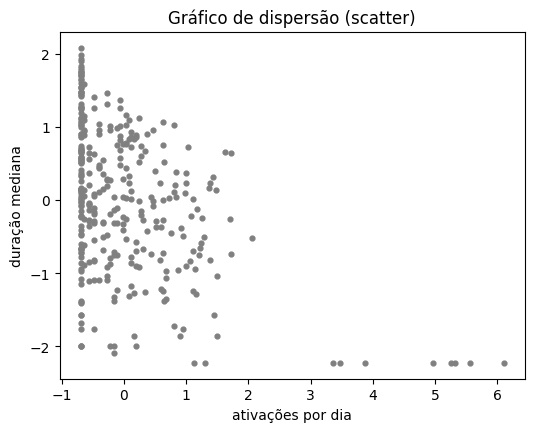

In [12]:
# Plot do grafico de dispersao, sem agrupamento

eixos = np.log10(tags[['ativacoes_dia', 'duracao_mediana_s']].clip(lower=0.5))
X = StandardScaler().fit_transform(eixos)

plt.figure(figsize=(6, 4.5))
plt.scatter(X[:, 0], X[:, 1], s=12, color='gray')
plt.xlabel('ativações por dia')
plt.ylabel('duração mediana')
plt.title('Gráfico de dispersão (scatter)')
plt.show()

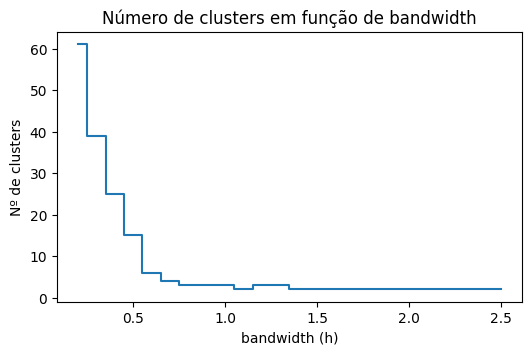

In [18]:
# Metodo para escolha de bandwidth(h) otimo

# Gera uma sequencia de valores para h, aplica o Mean Shift em cada e obtem o numero de cluster em cada
valores_h = np.round(np.arange(0.2, 2.51, 0.1), 2)
n_clusters = [len(MeanShift(bandwidth=h, bin_seeding=True).fit(X).cluster_centers_) for h in valores_h]

# Plot da variacao de numero de clusters por valor de bandwidth(h)
plt.figure(figsize=(6, 3.5))
plt.step(valores_h, n_clusters, where='mid')
#plt.yscale('log')
plt.xlabel('bandwidth (h)')
plt.ylabel('Nº de clusters')
plt.title('Número de clusters em função de bandwidth')
plt.show()

In [14]:
# Identificacao do maior trecho com o mesmo nº de clusters (> 1)
trechos = pd.DataFrame({'h': valores_h, 'n': n_clusters})
trechos['trecho'] = (trechos['n'] != trechos['n'].shift()).cumsum()
estaveis = trechos[trechos['n'] > 1].groupby('trecho')['h']
maior = estaveis.size().idxmax()

valores = estaveis.get_group(maior).values
h = valores[len(valores) // 2]
print(f'Bandwidth (h) definido: {h}')

Bandwidth (h) definido: 2.0


In [15]:
# Aplicacao do Mean Shift com o bandwidth (h) otimo
# bin_seeding=True torna o processo mais rapido, nem todos os pontos passam pelo processo, apenas os espacialmente distante
modelo = MeanShift(bandwidth=h, bin_seeding=True).fit(X)

tags['cluster'] = modelo.labels_
centros = modelo.cluster_centers_

print(f'{len(centros)} clusters')
tags['cluster'].value_counts()

2 clusters


,count
cluster,
0,326
1,8


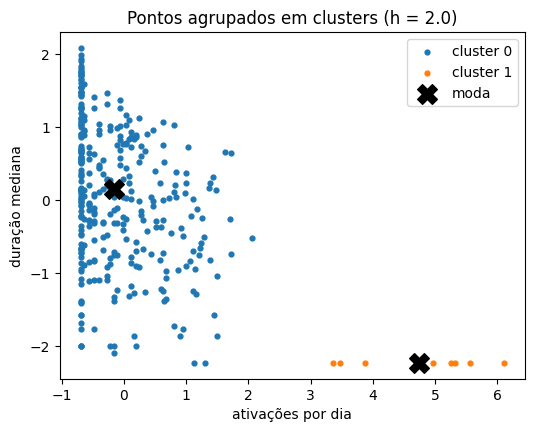

In [16]:
# Plot do grafico de dispersao com agrupamentos
plt.figure(figsize=(6, 4.5))
for k in sorted(tags['cluster'].unique()):
    pontos = X[tags['cluster'] == k]
    plt.scatter(pontos[:, 0], pontos[:, 1], s=12, label=f'cluster {k}')
plt.scatter(centros[:, 0], centros[:, 1], marker='X', s=200, color='black', label='moda')
plt.xlabel('ativações por dia')
plt.ylabel('duração mediana')
plt.title(f'Pontos agrupados em clusters (h = {h})')
plt.legend()
plt.show()